# 03 · Evaluación financiera: ¿dónde abrir el próximo Costco?

Convierte la demanda estimada en el notebook 02 en flujos de efectivo incrementales para Costco, y compara las tres opciones con VPN, TIR, periodo de recuperación, índice de rentabilidad e inversión máxima justificable. Además compara tres fuentes de financiamiento.

**Todas las cifras vienen de fuentes públicas verificables.** Cada supuesto que no tiene fuente se marca como *supuesto* y se somete a sensibilidad.

| Parámetro | Valor | Fuente |
|---|---|---|
| Margen bruto (incluye cuotas de membresía) | 12.03% de ingresos | Costco, Annual Report FY2025, Nota 11, segmento *Other International* (México, Japón, Reino Unido, etc.): ingresos 38,266, costo de mercancía 33,661 (mdd) |
| Gastos de operación sin depreciación | 6.83% | Mismo segmento: SG&A 2,949 menos D&A 335 |
| Depreciación de referencia | 0.88% de ingresos | Mismo segmento |
| Capital de trabajo | −1.10% de ingresos (Costco cobra antes de pagar) | Costco, balance al 30-ago-2026: inventarios 19,324; proveedores 22,591; ventas 297,247 |
| Venta promedio por tienda en México | 2,577 millones de pesos (2026) | Expansión 500: Costco de México 104,328 mdp en 2025, entre 42 tiendas, más inflación 2026 |
| Inversión por tienda | 35.4 a 100 mdd | Cota baja: activo fijo neto de *Other International* (6,189 mdd) / 175 almacenes. Cota alta: adiciones de activo fijo 703 mdd / 7 aperturas (FY2025), igual a lo reportado para Escobedo (Forbes México vía Mexico News Daily, 3-sep-2025) |
| ISR | 30% | Ley del ISR; Damodaran, *Country Risk*, ene-2026 |
| Tasa libre de riesgo EE. UU. | 4.94% | Damodaran, bono del Tesoro a 10 años, 1-nov-2026 |
| Prima de riesgo de capital, México | 6.69% (madura 4.23% + país 2.46%) | Damodaran, *ctryprem*, ene-2026 |
| Beta desapalancada | 0.80 (Retail: Grocery and Food) | Damodaran, *Betas*, ene-2026 |
| Inflación de largo plazo | México 3%, EE. UU. 2% | Metas de Banxico y de la Reserva Federal |
| TIIE 28 días | 6.5549% | Banxico SIE, cuadro CA51, 25-nov-2026 |
| Tipo de cambio FIX | 19.7040 pesos por dólar | Banxico SIE, cuadro CF373, 25-nov-2026 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROC = Path("../data/processed"); RES = Path("../resultados")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COL = {"Guadalajara": "#2a6fdb", "Monterrey": "#d1495b", "Querétaro": "#2e9e6a"}
ins = pd.read_csv(PROC / "insumos_financieros_zm.csv", index_col=0)
ins

,hogares_2026,tcma_hogares_2010_2020,demanda_2026,capacidad_2026,clubes,costco,venta_prom_costco_2026,venta_prom_sams_2026,k_calibracion,demanda_2026_B
zona_metropolitana,,,,,,,,,,
Guadalajara,1.820564e+06,0.030704,2.487095e+10,2.061208e+10,13,3,2.577150e+09,1.288063e+09,4.013542,2.278568e+10
Monterrey,2.077842e+06,0.035533,2.713312e+10,2.962955e+10,19,4,2.577150e+09,1.288063e+09,4.013542,1.933136e+10
Querétaro,6.078878e+05,0.049593,9.572154e+09,1.030655e+10,6,2,2.577150e+09,1.288063e+09,4.013542,1.223825e+10


## 1. Costo de capital (WACC) en pesos

1. **Costo del capital en dólares (CAPM con riesgo país):** $K_e^{USD} = R_f + \beta_L \times ERP_{México}$
2. **Beta apalancada (Hamada):** $\beta_L = \beta_U [1 + (1-t) D/E]$. Costco casi no tiene deuda: 6,162 mdd de deuda (balance ago-2026) contra unos 428,000 mdd de capitalización (443 millones de acciones a 966 dólares, precio promedio de recompra de agosto 2025, Annual Report FY2025).
3. **Conversión a pesos (paridad de Fisher internacional):** $K^{MXN} = (1+K^{USD}) \dfrac{1+\pi_{MX}}{1+\pi_{EU}} - 1$
4. **Costo de la deuda:** TIIE 28 + 1.0 punto de diferencial (*supuesto* para un emisor AA), después de impuestos.

In [2]:
P = dict(rf_usd=0.0494, erp_mx=0.0669, beta_u=0.80, t=0.30, deuda=6_162, cap_mercado=443.3 * 966,
         pi_mx=0.03, pi_us=0.02, tiie=0.065549, spread=0.010, fix=19.7040)
de = P["deuda"] / P["cap_mercado"]
beta_l = P["beta_u"] * (1 + (1 - P["t"]) * de)
ke_usd = P["rf_usd"] + beta_l * P["erp_mx"]
ke_mxn = (1 + ke_usd) * (1 + P["pi_mx"]) / (1 + P["pi_us"]) - 1
kd_mxn = (P["tiie"] + P["spread"]) * (1 - P["t"])
wd = de / (1 + de); we = 1 - wd
WACC = we * ke_mxn + wd * kd_mxn
wacc_tab = pd.Series({"D/E": de, "Beta apalancada": beta_l, "Ke en dólares": ke_usd, "Ke en pesos": ke_mxn,
                      "Kd en pesos después de impuestos": kd_mxn, "Peso de la deuda": wd, "WACC en pesos": WACC})
wacc_tab.to_frame("valor").style.format("{:.4f}")

,valor
D/E,0.0144
Beta apalancada,0.8081
Ke en dólares,0.1035
Ke en pesos,0.1143
Kd en pesos después de impuestos,0.0529
Peso de la deuda,0.0142
WACC en pesos,0.1134


## 2. Ventas incrementales: ingreso marginal de abrir una tienda más

Una tienda nueva no solo vende: también **le quita ventas a las tiendas Costco que ya existen** en la zona (canibalización, riesgo que el propio 10-K reconoce). Por eso usamos un modelo de reparto de mercado tipo Huff, con igual accesibilidad:

- Ventas totales de clubes en la zona: $S = \min(\text{Demanda}, \text{Capacidad})$. Si la demanda supera a la oferta, hay demanda no atendida.
- Cada club se lleva una parte de $S$ proporcional a su tamaño (venta promedio de su cadena).
- **Ingreso marginal para Costco** = ventas de todas las tiendas Costco de la zona *después* de abrir menos *antes* de abrir.

$$\Delta R = S_1 \frac{(n+1)w_C}{W+w_C} - S_0 \frac{n\,w_C}{W}$$

donde $n$ es el número de Costcos actuales, $w_C$ la venta de una tienda Costco promedio y $W$ la capacidad total actual.

In [3]:
def ingreso_marginal(demanda, W, n_costco, wc):
    S0, S1 = min(demanda, W), min(demanda, W + wc)
    venta_tienda_nueva = S1 * wc / (W + wc)
    antes, despues = S0 * n_costco * wc / W, S1 * (n_costco + 1) * wc / (W + wc)
    return pd.Series({"venta_tienda_nueva": venta_tienda_nueva, "ingreso_marginal": despues - antes,
                      "canibalizacion": venta_tienda_nueva - (despues - antes)})

wc = ins["venta_prom_costco_2026"].iloc[0]
esc = {}
for e, col in {"A": "demanda_2026", "B": "demanda_2026_B"}.items():
    esc[e] = ins.apply(lambda r: ingreso_marginal(r[col], r.capacidad_2026, r.costco, wc), axis=1)
im = pd.concat(esc, axis=1) / 1e6
im.round(1)

A                                  \
                   venta_tienda_nueva ingreso_marginal canibalizacion   
zona_metropolitana                                                      
Guadalajara                    2577.2           2577.2           -0.0   
Monterrey                      2171.2           1415.8          755.4   
Querétaro                      1914.7            957.2          957.6   

                                    B                                  
                   venta_tienda_nueva ingreso_marginal canibalizacion  
zona_metropolitana                                                     
Guadalajara                    2532.3           2397.8          134.5  
Monterrey                      1546.9           1008.7          538.2  
Querétaro                      2448.0           2189.8          258.2

**Lectura:** en Guadalajara (escenario A) la tienda nueva vende lo mismo que un Costco promedio y **no canibaliza**, porque atiende demanda que hoy no tiene club. En Monterrey y Querétaro una parte importante de lo que vendería se lo quita a otros Costcos.

## 3. Flujo de efectivo incremental a 20 años

- **Año 0 (2027):** inversión. 30% terreno (no se deprecia), 70% edificio y equipo (línea recta a 20 años) (*supuesto*).
- **Arranque:** el año 1 vende 80% y el año 2 90% de su nivel maduro (*supuesto*; el 10-K advierte que las tiendas nuevas tardan en madurar).
- **Crecimiento nominal de ventas:** inflación de 3% más el crecimiento de hogares de la zona, que suponemos baja a la mitad (años 1-10) y a la cuarta parte (años 11-20) de su ritmo 2010-2020 (*supuesto* conservador ante la falta de proyecciones municipales de CONAPO).
- **EBITDA incremental** $= 12.03\% \times \Delta R - 6.83\% \times \text{venta de la tienda nueva}$. El margen se gana sobre la venta realmente nueva, pero los gastos de operar el almacén dependen de todo lo que pasa por sus cajas.
- **Capex de mantenimiento:** 0.88% de la venta de la tienda (igual a la depreciación del segmento).
- **Valor terminal (año 20):** perpetuidad creciente al 3% (sin crecimiento real).

In [4]:
SUP = dict(margen_bruto=1 - 33_661 / 38_266, opex=(2_949 - 335) / 38_266, mant=335 / 38_266,
           ntc=(19_324 - 22_591) / 297_247, terreno=0.30, vida=20, rampa=(0.80, 0.90), g_terminal=0.03, anios=20)
CAPEX_USD = {"bajo": 6_189 / 175, "base": (6_189 / 175 + 703 / 7) / 2, "alto": 703 / 7}
print({k: f"{v:,.1f} mdd = {v * P['fix']:,.0f} mdp" for k, v in CAPEX_USD.items()})

def flujo(dR, venta_nueva, tcma, capex_mxn, wacc=WACC, s=SUP, margen=None, opex=None):
    margen = s["margen_bruto"] if margen is None else margen
    opex = s["opex"] if opex is None else opex
    anios = np.arange(0, s["anios"] + 1)
    g = np.array([0] + [(1 + P["pi_mx"]) * (1 + tcma * (0.5 if a <= 10 else 0.25)) - 1 for a in anios[1:]])
    nivel = np.cumprod(1 + g)                                   # índice de precios y hogares desde 2026
    rampa = np.array([0] + [s["rampa"][0], s["rampa"][1]] + [1] * (s["anios"] - 2))
    dR_t = dR * nivel * rampa; venta_t = venta_nueva * nivel * rampa
    ebitda = margen * dR_t - opex * venta_t
    dep = np.where(anios >= 1, capex_mxn * (1 - s["terreno"]) / s["vida"], 0)
    ebit = ebitda - dep
    impuestos = P["t"] * ebit          # Costco consolida: una pérdida reduce impuestos del grupo
    nopat = ebit - impuestos
    ntc = s["ntc"] * dR_t; d_ntc = np.diff(np.r_[0, ntc])
    capex = np.where(anios == 0, capex_mxn, s["mant"] * venta_t)
    fcf = nopat + dep - capex - d_ntc
    vt = fcf[-1] * (1 + s["g_terminal"]) / (wacc - s["g_terminal"])
    fcf_vt = fcf.copy(); fcf_vt[-1] += vt
    return pd.DataFrame({"año": 2026 + anios, "ingreso_marginal": dR_t, "venta_tienda": venta_t, "EBITDA": ebitda,
                         "depreciación": dep, "EBIT": ebit, "impuestos": impuestos, "NOPAT": nopat, "capex": capex,
                         "cambio_capital_trabajo": d_ntc, "FCF": fcf, "valor_terminal": np.where(anios == s["anios"], vt, 0),
                         "FCF_con_VT": fcf_vt})

def vpn(f, r): return np.sum(f / (1 + r) ** np.arange(len(f)))
def tir(f):
    lo, hi = -0.99, 1.0
    if vpn(f, lo) * vpn(f, hi) > 0: return np.nan
    for _ in range(200):
        mid = (lo + hi) / 2
        if vpn(f, lo) * vpn(f, mid) <= 0: hi = mid
        else: lo = mid
    return mid
def payback_desc(f, r):
    acum = np.cumsum(f / (1 + r) ** np.arange(len(f)))
    i = np.argmax(acum >= 0)
    return np.nan if acum[-1] < 0 else i - 1 + (-acum[i - 1]) / (acum[i] - acum[i - 1])

{'bajo': '35.4 mdd = 697 mdp', 'base': '67.9 mdd = 1,338 mdp', 'alto': '100.4 mdd = 1,979 mdp'}


## 4. Resultados: VPN, TIR, recuperación e inversión máxima justificable

In [5]:
filas, flujos = [], {}
for e in ["A", "B"]:
    for zm in ins.index:
        r = esc[e].loc[zm]; tcma = ins.loc[zm, "tcma_hogares_2010_2020"]
        for nivel_capex, usd in CAPEX_USD.items():
            capex = usd * 1e6 * P["fix"]
            f = flujo(r.ingreso_marginal, r.venta_tienda_nueva, tcma, capex)
            flujos[(e, zm, nivel_capex)] = f
            v = vpn(f.FCF_con_VT.values, WACC)
            # inversión máxima con VPN = 0 (el VPN es lineal en el capex)
            f0 = flujo(r.ingreso_marginal, r.venta_tienda_nueva, tcma, 0); v0 = vpn(f0.FCF_con_VT.values, WACC)
            f1 = flujo(r.ingreso_marginal, r.venta_tienda_nueva, tcma, 1e9); v1 = vpn(f1.FCF_con_VT.values, WACC)
            capex_max = v0 / ((v0 - v1) / 1e9)
            filas.append({"escenario": e, "zona": zm, "capex": nivel_capex, "capex_mdp": capex / 1e6,
                          "ingreso_marginal_2026_mdp": r.ingreso_marginal / 1e6,
                          "VPN_mdp": v / 1e6, "TIR": tir(f.FCF_con_VT.values), "TIR_sin_VT": tir(f.FCF.values),
                          "payback_desc_años": payback_desc(f.FCF_con_VT.values, WACC),
                          "IR": 1 + v / capex, "capex_max_mdp": capex_max / 1e6, "capex_max_mdd": capex_max / P["fix"] / 1e6})
res = pd.DataFrame(filas)
res.to_csv(RES / "tablas/03_resultados_vpn_tir.csv", index=False)
res[res.capex == "base"].set_index(["escenario", "zona"]).drop(columns="capex").round(3)

capex_mdp  ingreso_marginal_2026_mdp   VPN_mdp    TIR  \
escenario zona                                                                 
A         Guadalajara   1337.845                   2577.150  -176.047  0.099   
          Monterrey     1337.845                   1415.783 -1235.875 -0.100   
          Querétaro     1337.845                    957.177 -1611.961    NaN   
B         Guadalajara   1337.845                   2397.754  -353.724  0.084   
          Monterrey     1337.845                   1008.694 -1227.915 -0.088   
          Querétaro     1337.845                   2189.816  -471.637  0.073   

                       TIR_sin_VT  payback_desc_años     IR  capex_max_mdp  \
escenario zona                                                               
A         Guadalajara       0.065                NaN  0.868       1142.906   
          Monterrey        -0.148                NaN  0.076        -30.656   
          Querétaro           NaN                NaN -0.205       -447.100   
B         Guadalajara       0.048                NaN  0.736        946.163   
          Monterrey        -0.138                NaN  0.082        -21.841   
          Querétaro         0.035                NaN  0.647        815.595   

                       capex_max_mdd  
escenario zona                        
A         Guadalajara         58.004  
          Monterrey           -1.556  
          Querétaro          -22.691  
B         Guadalajara         48.019  
          Monterrey           -1.108  
          Querétaro           41.392

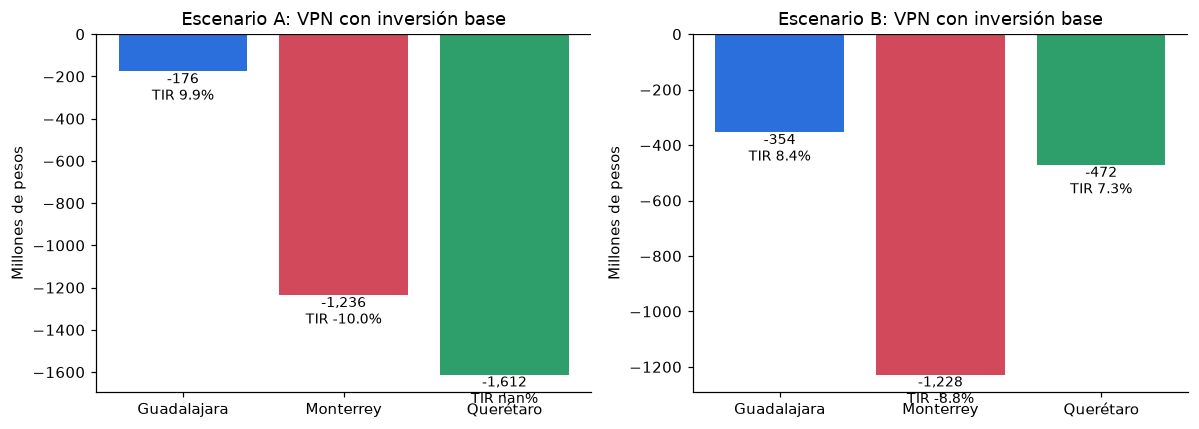

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
base = res[res.capex == "base"]
for i, e in enumerate(["A", "B"]):
    s = base[base.escenario == e].set_index("zona")
    ax[i].bar(s.index, s.VPN_mdp, color=[COL[z] for z in s.index])
    ax[i].axhline(0, color="black", lw=0.8)
    for j, (z, v) in enumerate(s.VPN_mdp.items()):
        ax[i].annotate(f"{v:,.0f}\nTIR {s.loc[z, 'TIR']:.1%}", (j, v), ha="center", va="bottom" if v > 0 else "top", fontsize=9)
    ax[i].set(title=f"Escenario {e}: VPN con inversión base", ylabel="Millones de pesos")
plt.tight_layout(); plt.savefig(RES / "graficos/03_vpn_escenarios.png", bbox_inches="tight"); plt.show()

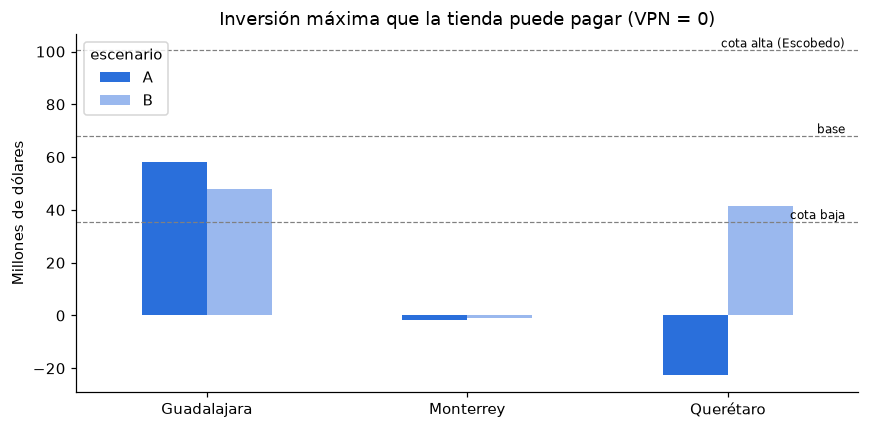

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
cm = res[res.capex == "base"].pivot(index="zona", columns="escenario", values="capex_max_mdd")
cm.plot.bar(ax=ax, color=["#2a6fdb", "#9ab8ee"], rot=0)
for y, lab in [(CAPEX_USD["bajo"], "cota baja"), (CAPEX_USD["base"], "base"), (CAPEX_USD["alto"], "cota alta (Escobedo)")]:
    ax.axhline(y, ls="--", color="grey", lw=0.8); ax.annotate(lab, (2.45, y), fontsize=8, va="bottom", ha="right")
ax.set(title="Inversión máxima que la tienda puede pagar (VPN = 0)", ylabel="Millones de dólares", xlabel="")
plt.tight_layout(); plt.savefig(RES / "graficos/03_capex_maximo.png", bbox_inches="tight"); plt.show()

## 5. Costo marginal vs. ingreso marginal (por año, nivel maduro)

El **costo marginal anual** de la tienda incluye el costo de la mercancía vendida de más, la operación del almacén y el **costo anual equivalente de la inversión** (anualidad):

$$CAE = I \cdot \frac{r}{1-(1+r)^{-n}}$$

Abrir conviene si el ingreso marginal anual supera al costo marginal anual.

In [8]:
def anualidad(I, r, n): return I * r / (1 - (1 + r) ** -n)
mg = []
for e in ["A", "B"]:
    for zm in ins.index:
        r = esc[e].loc[zm]; capex = CAPEX_USD["base"] * 1e6 * P["fix"]
        costo_merc = (1 - SUP["margen_bruto"]) * r.ingreso_marginal
        costo_op = (SUP["opex"] + SUP["mant"]) * r.venta_tienda_nueva
        cae = anualidad(capex, WACC, 20)
        im_ = r.ingreso_marginal
        mg.append({"escenario": e, "zona": zm, "ingreso_marginal": im_ / 1e6, "costo_mercancía": costo_merc / 1e6,
                   "costo_operación": costo_op / 1e6, "costo_capital_anualizado (CAE)": cae / 1e6,
                   "costo_marginal_total": (costo_merc + costo_op + cae) / 1e6,
                   "beneficio_marginal_antes_imp": (im_ - costo_merc - costo_op - cae) / 1e6})
mg = pd.DataFrame(mg).set_index(["escenario", "zona"]).round(1)
mg.to_csv(RES / "tablas/03_ingreso_costo_marginal.csv")
mg

ingreso_marginal  costo_mercancía  costo_operación  \
escenario zona                                                              
A         Guadalajara            2577.2           2267.0            198.6   
          Monterrey              1415.8           1245.4            167.3   
          Querétaro               957.2            842.0            147.6   
B         Guadalajara            2397.8           2109.2            195.2   
          Monterrey              1008.7            887.3            119.2   
          Querétaro              2189.8           1926.3            188.7   

                       costo_capital_anualizado (CAE)  costo_marginal_total  \
escenario zona                                                                
A         Guadalajara                           171.8                2637.4   
          Monterrey                             171.8                1584.5   
          Querétaro                             171.8                1161.3   
B         Guadalajara                           171.8                2476.1   
          Monterrey                             171.8                1178.3   
          Querétaro                             171.8                2286.7   

                       beneficio_marginal_antes_imp  
escenario zona                                       
A         Guadalajara                         -60.2  
          Monterrey                          -168.7  
          Querétaro                          -204.1  
B         Guadalajara                         -78.4  
          Monterrey                          -169.6  
          Querétaro                           -96.9

## 6. Sensibilidad (Guadalajara vs. Querétaro, escenario B, inversión base)

Movemos cada supuesto ±20% (o el rango indicado) y vemos cuánto cambia el VPN. Las barras más largas son los supuestos que más importan.

In [9]:
def vpn_caso(zm, e="B", capex_usd=CAPEX_USD["base"], wacc=WACC, margen=None, opex=None, demanda_mult=1.0, rampa=None, g_term=None):
    s = SUP.copy()
    if rampa: s["rampa"] = rampa
    if g_term is not None: s["g_terminal"] = g_term
    col = "demanda_2026" if e == "A" else "demanda_2026_B"
    r = ingreso_marginal(ins.loc[zm, col] * demanda_mult, ins.loc[zm, "capacidad_2026"], ins.loc[zm, "costco"], wc)
    f = flujo(r.ingreso_marginal, r.venta_tienda_nueva, ins.loc[zm, "tcma_hogares_2010_2020"], capex_usd * 1e6 * P["fix"],
              wacc=wacc, s=s, margen=margen, opex=opex)
    return vpn(f.FCF_con_VT.values, wacc) / 1e6

pruebas = {
    "Inversión baja": dict(capex_usd=CAPEX_USD["bajo"]), "Inversión alta": dict(capex_usd=CAPEX_USD["alto"]),
    "WACC −1 pp": dict(wacc=WACC - 0.01), "WACC +1 pp": dict(wacc=WACC + 0.01),
    "Margen bruto −0.5 pp": dict(margen=SUP["margen_bruto"] - 0.005), "Margen bruto +0.5 pp": dict(margen=SUP["margen_bruto"] + 0.005),
    "Demanda −20%": dict(demanda_mult=0.8), "Demanda +20%": dict(demanda_mult=1.2),
    "Gastos de operación −1 pp": dict(opex=SUP["opex"] - 0.01), "Gastos de operación +1 pp": dict(opex=SUP["opex"] + 0.01),
    "Arranque lento (60%, 80%)": dict(rampa=(0.6, 0.8)), "Crecimiento terminal 2%": dict(g_term=0.02),
}
sens = pd.DataFrame({zm: {k: vpn_caso(zm, **v) for k, v in pruebas.items()} for zm in ["Guadalajara", "Querétaro", "Monterrey"]})
sens.loc["Caso base (B)"] = [vpn_caso(z) for z in sens.columns]
sens.round(0).to_csv(RES / "tablas/03_sensibilidad.csv")
sens.round(0)

,Guadalajara,Querétaro,Monterrey
Inversión baja,225.0,107.0,-649.0
Inversión alta,-933.0,-1051.0,-1807.0
WACC −1 pp,-216.0,-348.0,-1217.0
WACC +1 pp,-461.0,-568.0,-1236.0
Margen bruto −0.5 pp,-470.0,-588.0,-1278.0
Margen bruto +0.5 pp,-237.0,-355.0,-1178.0
Demanda −20%,-1299.0,-1621.0,-1224.0
Demanda +20%,-176.0,-80.0,-1232.0
Gastos de operación −1 pp,-107.0,-211.0,-1074.0
Gastos de operación +1 pp,-600.0,-732.0,-1382.0


## 7. Matriz de decisión

Ordenamos las zonas por cada criterio cuantitativo en ambos escenarios (1 = mejor).

In [10]:
b = res[res.capex == "base"].copy()
crit = {"VPN_mdp": False, "TIR": False, "capex_max_mdd": False, "ingreso_marginal_2026_mdp": False}
rank = pd.concat({e: b[b.escenario == e].set_index("zona")[list(crit)].rank(ascending=False) for e in ["A", "B"]}, axis=1)
canib = im.xs("canibalizacion", axis=1, level=1).rank()
rank[("A", "canibalización")] = canib["A"]; rank[("B", "canibalización")] = canib["B"]
rank["promedio"] = rank.mean(axis=1)
rank = rank.sort_values("promedio")
rank.to_csv(RES / "tablas/03_matriz_decision.csv")
rank

A                                                    B       \
            VPN_mdp  TIR capex_max_mdd ingreso_marginal_2026_mdp VPN_mdp  TIR   
zona                                                                            
Guadalajara     1.0  1.0           1.0                       1.0     1.0  1.0   
Querétaro       3.0  NaN           3.0                       3.0     2.0  2.0   
Monterrey       2.0  2.0           2.0                       2.0     3.0  3.0   

                                                                 A  \
            capex_max_mdd ingreso_marginal_2026_mdp canibalización   
zona                                                                 
Guadalajara           1.0                       1.0            1.0   
Querétaro             2.0                       2.0            3.0   
Monterrey             3.0                       3.0            2.0   

                         B  promedio  
            canibalización            
zona                                  
Guadalajara            1.0  1.000000  
Querétaro              2.0  2.444444  
Monterrey              3.0  2.500000

### Conclusión del análisis financiero

1. **Guadalajara es la mejor opción en todos los criterios y en ambos escenarios.** Es la zona con más demanda no atendida, la única donde una tienda nueva casi no canibaliza a los Costcos existentes, y la que justifica la mayor inversión.
2. **Querétaro es la segunda opción**, pero solo si se acepta el escenario B (que sus hogares compran más de lo que predice su perfil). En el escenario A la tienda de Corregidora ya cubre la zona.
3. **Monterrey se descarta:** con 19 clubes (incluido el nuevo Costco de Escobedo), más de la mitad de las ventas de una tienda nueva se las quitaría a otros Costcos. Su VPN es negativo aun con la inversión más baja.
4. **Regla de decisión:** como Costco no publica cuánto invierte por tienda, la cifra clave es la **inversión máxima justificable**. En Guadalajara, abrir crea valor si la tienda cuesta menos de unos 48 mdd (escenario B) a 58 mdd (escenario A). Eso está por debajo de los 100 mdd de Escobedo (la tienda más grande de América Latina), así que el proyecto debe diseñarse con un formato estándar y, de preferencia, con el terreno arrendado: 56 de los 175 almacenes de *Other International* operan con arrendamiento (Annual Report FY2025).

## 8. Fuentes de financiamiento (tres opciones reales)

| Opción | Costo | Fuente del dato |
|---|---|---|
| 1. Recursos propios (caja de Costco: 20,207 mdd al 30-ago-2026) | Costo de oportunidad = $K_e$ en pesos | Comunicado de resultados FY2026; Damodaran |
| 2. Crédito bancario o certificado bursátil en pesos (BMV/BIVA), tasa TIIE + 1.0 pp, amortizable a 10 años | $(TIIE + 1)(1-t)$ | Banxico (TIIE); emisión supervisada por la CNBV |
| 3. Bono corporativo en dólares (Costco tiene calificación AA de S&P y Fitch), tasa Tesoro + 0.6 pp (*supuesto* de diferencial AA) | Después de impuestos y ajustado por la depreciación esperada del peso | Damodaran (Tesoro), S&P y Fitch |

Para comparar una deuda en dólares con una en pesos se usa la **paridad de tasas**: el costo en pesos de pagar en dólares es $(1+i_{USD})\frac{1+\pi_{MX}}{1+\pi_{EU}} - 1$, porque el peso tiende a depreciarse al ritmo del diferencial de inflación.

In [11]:
monto = CAPEX_USD["base"] * 1e6 * P["fix"]
i_mxn = P["tiie"] + P["spread"]
i_usd = P["rf_usd"] + 0.006
i_usd_en_pesos = (1 + i_usd) * (1 + P["pi_mx"]) / (1 + P["pi_us"]) - 1
fin = pd.DataFrame({
    "costo antes de impuestos": [ke_mxn, i_mxn, i_usd_en_pesos],
    "costo después de impuestos": [ke_mxn, i_mxn * (1 - P["t"]), i_usd_en_pesos * (1 - P["t"])],
    "riesgo cambiario": ["No", "No", "Sí: pasivo en dólares contra ingresos en pesos"],
}, index=["1. Recursos propios", "2. Crédito/CEBURE en pesos (TIIE+1)", "3. Bono en dólares (Tesoro+0.6)"])
fin.to_csv(RES / "tablas/03_fuentes_financiamiento.csv")

# Tabla de amortización del crédito en pesos (anualidad)
pago = anualidad(monto, i_mxn, 10)
saldo, tabla = monto, []
for a in range(1, 11):
    interes = saldo * i_mxn; capital = pago - interes; saldo -= capital
    tabla.append({"año": a, "pago": pago / 1e6, "interés": interes / 1e6, "escudo fiscal": interes * P["t"] / 1e6,
                  "amortización": capital / 1e6, "saldo": max(saldo, 0) / 1e6})
amort = pd.DataFrame(tabla).round(2)
amort.to_csv(RES / "tablas/03_amortizacion_credito.csv", index=False)

# Valuación de un bono: precio del bono en dólares (cupón 5%, 10 años) ante distintas tasas de mercado
def precio_bono(cupon, ytm, n, vn=100): return sum(cupon * vn / (1 + ytm) ** k for k in range(1, n + 1)) + vn / (1 + ytm) ** n
bono = pd.Series({f"rendimiento {y:.2%}": precio_bono(0.05, y, 10) for y in [i_usd - 0.01, i_usd, i_usd + 0.01]}).round(2)
print(f"Pago anual del crédito: {pago/1e6:,.1f} mdp | Bono 5% a 10 años, precio por 100 de valor nominal:"); print(bono)
fin.style.format({"costo antes de impuestos": "{:.2%}", "costo después de impuestos": "{:.2%}"})

Pago anual del crédito: 195.4 mdp | Bono 5% a 10 años, precio por 100 de valor nominal:
rendimiento 4.54%    103.63
rendimiento 5.54%     95.94
rendimiento 6.54%     88.95
dtype: float64


,costo antes de impuestos,costo después de impuestos,riesgo cambiario
1. Recursos propios,11.43%,11.43%,No
2. Crédito/CEBURE en pesos (TIIE+1),7.55%,5.29%,No
3. Bono en dólares (Tesoro+0.6),6.57%,4.60%,Sí: pasivo en dólares contra ingresos en pesos


In [12]:
amort

,año,pago,interés,escudo fiscal,amortización,saldo
0,1,195.39,101.07,30.32,94.32,1243.52
1,2,195.39,93.95,28.18,101.45,1142.08
2,3,195.39,86.28,25.88,109.11,1032.97
3,4,195.39,78.04,23.41,117.35,915.61
4,5,195.39,69.17,20.75,126.22,789.39
5,6,195.39,59.64,17.89,135.76,653.63
6,7,195.39,49.38,14.81,146.01,507.62
7,8,195.39,38.35,11.51,157.04,350.58
8,9,195.39,26.49,7.95,168.91,181.67
9,10,195.39,13.72,4.12,181.67,0.00


## 9. Exportar a Excel (flujos con fórmulas de VPN y TIR)

Cada hoja tiene el flujo de una zona en el escenario B con inversión base. Las celdas de VPN y TIR son fórmulas de Excel (`=VNA` y `=TIR`), así que se pueden auditar y modificar en clase.

In [13]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill
wb = Workbook(); wb.remove(wb.active)
ws = wb.create_sheet("Supuestos")
for i, (k, v) in enumerate(list(wacc_tab.items()) + [("Margen bruto", SUP["margen_bruto"]), ("Opex/ventas", SUP["opex"]),
                            ("Capex mant./ventas", SUP["mant"]), ("Capital de trabajo/ventas", SUP["ntc"]),
                            ("Tipo de cambio FIX", P["fix"]), ("Inversión base (mdd)", CAPEX_USD["base"])], start=1):
    ws.cell(i, 1, k); ws.cell(i, 2, float(v))
ws.column_dimensions["A"].width = 34
for zm in ins.index:
    f = flujos[("B", zm, "base")]
    ws = wb.create_sheet(zm[:30])
    cols = ["año", "ingreso_marginal", "venta_tienda", "EBITDA", "depreciación", "EBIT", "impuestos", "NOPAT", "capex",
            "cambio_capital_trabajo", "FCF", "valor_terminal", "FCF_con_VT"]
    for j, c in enumerate(cols, start=1):
        ws.cell(1, j, c).font = Font(bold=True, color="FFFFFF"); ws.cell(1, j).fill = PatternFill("solid", fgColor="1F4E79")
        for i, v in enumerate(f[c].values, start=2):
            ws.cell(i, j, float(v) if c != "año" else int(v))
    n = len(f) + 1
    ws.cell(n + 2, 1, "WACC"); ws.cell(n + 2, 2, float(WACC))
    ws.cell(n + 3, 1, "VPN"); ws.cell(n + 3, 2, f"=M2+NPV(B{n+2},M3:M{n})")
    ws.cell(n + 4, 1, "TIR"); ws.cell(n + 4, 2, f"=IRR(M2:M{n})")
    for c in "BCDEFGHIJKLM": ws.column_dimensions[c].width = 16
wb.save(RES / "tablas/03_flujos_costco.xlsx")
print("Guardado resultados/tablas/03_flujos_costco.xlsx")

Guardado resultados/tablas/03_flujos_costco.xlsx
